# BPIC-17 — Section 2.3: event log abstraction and process discovery (W_ + O_ + A_ level)

The final process model is the **base model for a simulation**, so it has to show the work of the bank
(W_ work items). A_ activities that only duplicate W_ work are replaced by the corresponding W_ activities.

This notebook
1. builds the event log with **16 activities** (`src/abstraction_w.py`),
2. reports the statistics for Table 2a,
3. checks the abstraction (replaced A_/W_ pairs, O_Cancelled, directly-follows graph),
4. discovers models with the Inductive Miner (noise 0.0 / 0.2 / 0.4) and the Heuristics Miner,
5. evaluates them on the test set (`src/evaluation.py`).

## 0. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"  # no progress bars (must be set before tqdm is imported)
from pathlib import Path
import shutil
import warnings

import numpy as np
import pandas as pd
import pm4py
from IPython.display import display

from src.prep import CASE, ACT, TS, LC, SEED, load_event_log, drop_open_cases, split_cases, filter_top_variants
from src import abstraction_w as aw
from src.evaluation import evaluate

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200, "display.width", 250)

GRAPHVIZ_FALLBACK = Path("/opt/anaconda3/envs/graphviz/bin")
if shutil.which("dot") is None and (GRAPHVIZ_FALLBACK / "dot").exists():
    os.environ["PATH"] = f"{GRAPHVIZ_FALLBACK}{os.pathsep}{os.environ['PATH']}"
assert shutil.which("dot"), "Graphviz (dot) is needed for the figures"

DATA_DIR = Path("BPIC-17 Data")
MODEL_DIR = Path("models/discovery"); MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures/discovery"); FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR = Path("tables"); TAB_DIR.mkdir(exist_ok=True)
SPLIT_DIR = Path("splits")

LEVEL = aw.LEVEL         # "L3_WOA"
TEST_SHARE = 0.3         # same split as before (seed 42)
COVERAGE = 0.9           # discovery log: variants covering 90 % of the training cases
IM_NOISE = [0.0, 0.2, 0.4]
HM_PARAMS = {"dependency_threshold": 0.5, "and_threshold": 0.65, "loop_two_threshold": 0.5}  # as before
print("pm4py", pm4py.__version__, "| seed", SEED)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.12 | seed 42


## 1. New event log (16 activities)

* W_ (5): one event per started work item instance; timestamp = first start; attributes `w_duration_h`
  (first start to end), `w_end` (complete / ate_abort / withdraw / unfinished) and the resource of the first start.
* O_ (6): `O_Sent (mail and online)` and `O_Sent (online only)` are merged into `O_Sent` (attribute `channel`).
* A_ (5): `A_Create Application`, `A_Submitted` (online application), `A_Pending`, `A_Denied`, `A_Cancelled`.
* Open cases (no outcome) are removed as before.

In [2]:
df_all = load_event_log(DATA_DIR / "BPI Challenge 2017.xes", DATA_DIR / "bpic17_eventlog.pkl")
df, n_open = drop_open_cases(df_all)
print(f"original log: {df_all[CASE].nunique():,} cases | open cases removed: {n_open} | closed: {df[CASE].nunique():,}")

log, report = aw.build_log(df)  # built on the closed cases
for k, v in report.items():
    print(f"{k}: {v}")

original log: 31,509 cases | open cases removed: 98 | closed: 31,411


W instances: 148154
W instances never started (dropped): 21740
W instances never started, by end: {'withdraw': 21740}
W events (started instances): 126414
W events by end type: {'ate_abort': 84930, 'complete': 41484}
irregular lifecycle sequences: {'repeated start within an instance (ignored)': 981}


In [3]:
removed_w = pd.DataFrame({
    "cases (all)": [df_all.loc[df_all[ACT] == a, CASE].nunique() for a in aw.W_REMOVED],
    "cases (closed)": [df.loc[df[ACT] == a, CASE].nunique() for a in aw.W_REMOVED],
    "events (closed)": [int((df[ACT] == a).sum()) for a in aw.W_REMOVED],
}, index=aw.W_REMOVED)
any_removed = df.loc[df[ACT].isin(aw.W_REMOVED), CASE].nunique()
print(f"closed cases with at least one of the three removed W_ activities: {any_removed}")
removed_w

closed cases with at least one of the three removed W_ activities: 378


,cases (all),cases (closed),events (closed)
W_Assess potential fraud,303,303,3282
W_Shortened completion,74,74,238
W_Personal Loan collection,2,2,22


In [4]:
activity_table = (log.groupby(ACT).agg(events=(CASE, "size"), cases=(CASE, "nunique"))
                  .reindex(aw.ACTIVITIES))
n_cases = log[CASE].nunique()
activity_table["% of cases"] = (100 * activity_table["cases"] / n_cases).round(1)
activity_table["per case (all cases)"] = (activity_table["events"] / n_cases).round(2)
activity_table["per case (if present)"] = (activity_table["events"] / activity_table["cases"]).round(2)
activity_table["max per case"] = log.groupby([CASE, ACT]).size().groupby(level=1).max().reindex(aw.ACTIVITIES)
activity_table.to_csv(TAB_DIR / "w_level_activities.csv")
print(f"{n_cases:,} cases, {len(log):,} events, {log[ACT].nunique()} activities")
activity_table

31,411 cases, 360,016 events, 16 activities


,events,cases,% of cases,per case (all cases),per case (if present),max per case
concept:name,,,,,,
W_Handle leads,3622,3621,11.5,0.12,1.00,2
W_Complete application,29574,29551,94.1,0.94,1.00,3
W_Call after offers,31328,31264,99.5,1.00,1.00,3
W_Validate application,38922,21825,69.5,1.24,1.78,9
W_Call incomplete files,22968,14958,47.6,0.73,1.54,7
O_Create Offer,42815,31411,100.0,1.36,1.36,10
O_Sent,41554,31264,99.5,1.32,1.33,10
O_Returned,23256,21723,69.2,0.74,1.07,3
O_Accepted,17228,17228,54.8,0.55,1.00,1


In [5]:
# W_ work items: end type and duration (first start -> end) for the simulation
w = log[log[ACT].isin(aw.W_KEEP)]
w_summary = pd.concat([
    pd.crosstab(w[ACT], w["w_end"]),
    w.groupby(ACT)["w_duration_h"].describe(percentiles=[0.5])[["mean", "50%", "max"]]
     .round(2).rename(columns={"mean": "duration mean (h)", "50%": "duration median (h)", "max": "duration max (h)"}),
], axis=1).reindex(aw.W_KEEP)
w_summary

,ate_abort,complete,duration mean (h),duration median (h),duration max (h)
concept:name,,,,,
W_Handle leads,149,3473,0.40,0.02,114.09
W_Complete application,10513,19061,23.33,0.62,765.91
W_Call after offers,30986,342,336.59,208.58,1920.32
W_Validate application,23106,15816,39.81,20.43,671.48
W_Call incomplete files,20176,2792,95.65,26.22,3362.43


## 2. Statistics for Table 2a

Same columns as the existing rows of Table 2a. The rows of Table 2a are computed on **all 31,509 cases**
(open cases included); for comparison the new level is shown both on all cases and on the closed cases.

In [6]:
log_all_cases, _ = aw.build_log(df_all)
table2a = pd.DataFrame({"W_ + O_ + A_ (16 activities), all cases": aw.coverage_stats(log_all_cases),
                        "W_ + O_ + A_ (16 activities), closed cases": aw.coverage_stats(log)}).T
table2a.to_csv(TAB_DIR / "w_level_table2a.csv")
table2a

,cases,events,variants,top-10 variants % cases,variants for 80 % cases
"W_ + O_ + A_ (16 activities), all cases",31509.0,361008.0,2912.0,48.5,100.0
"W_ + O_ + A_ (16 activities), closed cases",31411.0,360016.0,2864.0,48.7,97.0


## 3. Checks

### 3.1 Replaced A_ / W_ pairs (original log, all cases)

Order: first event of the A_ activity vs. the first `start` of the W_ activity, for cases that contain both
(and a started W_ instance).

In [7]:
pairs = aw.pair_check(df_all)
pairs.to_csv(TAB_DIR / "w_level_pair_check.csv", index=False)
pairs

,A activity,W activity,cases,both,only A,only W,neither,A before W start %,same time %,A after W start %,median A - W start (h)
0,A_Submitted,W_Handle leads,31509,20423,0,0,11086,100.0,0.0,0.0,-1.07
1,A_Concept,W_Complete application,31509,31509,0,0,0,62.5,0.0,37.5,-0.24
2,A_Accepted,W_Complete application,31509,31509,0,0,0,0.2,0.0,99.8,0.26
3,A_Complete,W_Call after offers,31509,31362,0,0,147,0.0,0.0,100.0,0.00
4,A_Validating,W_Validate application,31509,21870,0,0,9639,0.0,0.0,100.0,0.00
5,A_Incomplete,W_Call incomplete files,31509,15003,0,0,16506,0.0,0.0,100.0,0.00


### 3.2 O_Cancelled events (original log, all cases)

* **after outcome**: an `A_Pending`, `A_Denied` or `A_Cancelled` happened before it in the case;
* **replacement**: otherwise, a new `O_Create Offer` follows later in the case;
* **other**: neither.

`both definitions` counts events that are after an outcome *and* followed by a new offer (classified as "after outcome").

In [8]:
oc = aw.classify_o_cancelled(df_all)
oc_table = oc.groupby("class").agg(events=(CASE, "size"), cases=(CASE, "nunique"))
oc_table["% of events"] = (100 * oc_table["events"] / len(oc)).round(1)
oc_table.loc["total"] = [len(oc), oc[CASE].nunique(), 100.0]
oc_table.to_csv(TAB_DIR / "w_level_o_cancelled.csv")
print("events matching both definitions:", int(oc["both definitions"].sum()))
oc_table

events matching both definitions: 0


,events,cases,% of events
class,,,
after outcome,18810,14706,90.0
other,1045,880,5.0
replacement,1043,838,5.0
total,20898,15682,100.0


### 3.3 Directly-follows graph of the new log (closed cases)

In [9]:
dfg, starts, ends = pm4py.discover_dfg(log, activity_key=ACT, case_id_key=CASE, timestamp_key=TS)
pm4py.save_vis_dfg(dfg, starts, ends, str(FIG_DIR / f"{LEVEL}_dfg.pdf"), rankdir="LR")

nxt = log.groupby(CASE, sort=False)[ACT].shift(-1)
pairs_df = pd.DataFrame({"from": log[ACT], "to": nxt, CASE: log[CASE]}).dropna()
dfg_table = (pairs_df.groupby(["from", "to"]).agg(frequency=(CASE, "size"), cases=(CASE, "nunique"))
             .sort_values("frequency", ascending=False))
dfg_table["% of cases"] = (100 * dfg_table["cases"] / n_cases).round(1)
dfg_table.to_csv(TAB_DIR / "w_level_dfg.csv")
print(f"{len(dfg_table)} directly-follows relations; start activities: {starts}; end activities: {ends}")
dfg_table.head(25)

86 directly-follows relations; start activities: {'A_Create Application': 31411}; end activities: {'O_Cancelled': 14706, 'A_Pending': 12792, 'O_Refused': 3719, 'A_Cancelled': 161, 'A_Denied': 33}


,,frequency,cases,% of cases
from,to,,,
O_Create Offer,O_Sent,37953,31120,99.1
O_Sent,W_Call after offers,31273,31264,99.5
W_Complete application,O_Create Offer,29530,29530,94.0
W_Validate application,O_Returned,21501,20756,66.1
A_Create Application,A_Submitted,20339,20339,64.8
W_Call after offers,W_Validate application,18524,18517,59.0
O_Accepted,A_Pending,17228,17228,54.8
A_Submitted,W_Complete application,14865,14865,47.3
W_Call incomplete files,W_Validate application,14288,10478,33.4


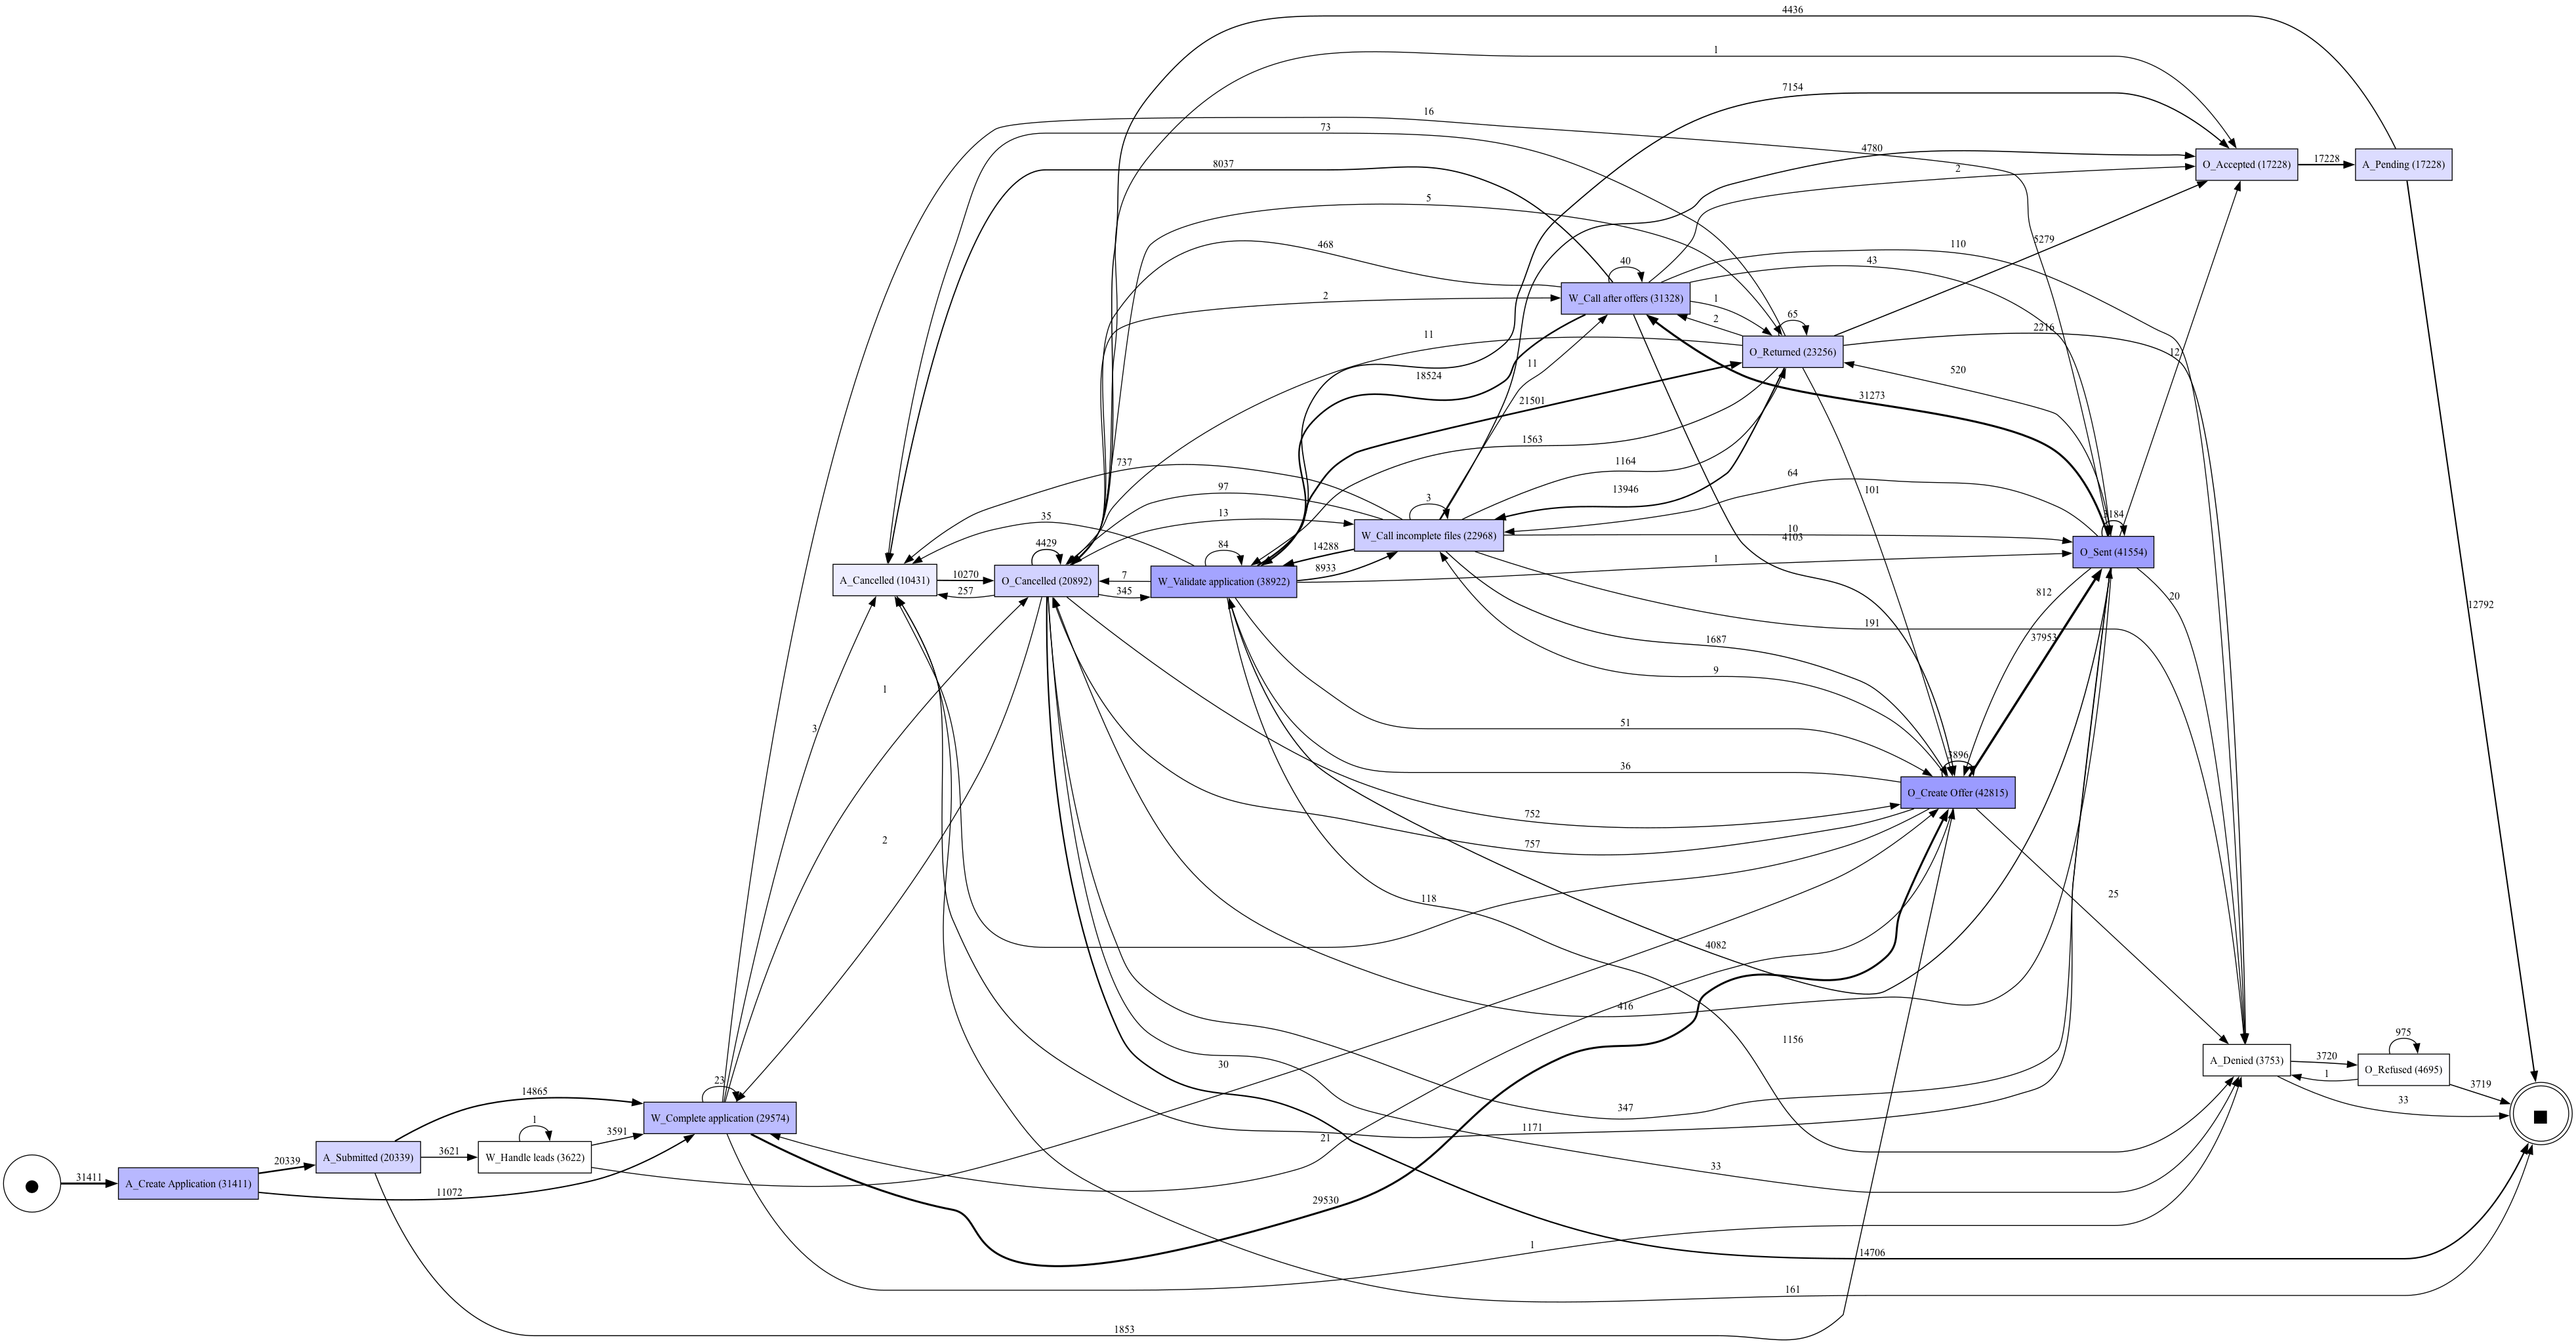

In [10]:
pm4py.view_dfg(dfg, starts, ends, rankdir="LR")

## 4. Train/test split and discovery log

The same case-level split as before (70/30, seed 42, `splits/`). The split is recomputed and checked
against the saved case ids.

In [11]:
train_ids, test_ids = split_cases(log[CASE].unique(), test_share=TEST_SHARE, seed=SEED)
saved_train = (SPLIT_DIR / "train_cases.txt").read_text().split("\n")
saved_test = (SPLIT_DIR / "test_cases.txt").read_text().split("\n")
assert sorted(train_ids) == sorted(saved_train) and sorted(test_ids) == sorted(saved_test), "split differs"
train = log[log[CASE].isin(set(train_ids))]
test = log[log[CASE].isin(set(test_ids))][[CASE, ACT, TS]]
disc, k = filter_top_variants(train, COVERAGE)
print(f"train {len(train_ids):,} | test {len(test_ids):,} cases")
print(f"discovery log: {k} of {train.groupby(CASE)[ACT].agg(tuple).nunique()} training variants, "
      f"{disc[CASE].nunique():,} cases ({100 * disc[CASE].nunique() / len(train_ids):.1f} %)")

train 21,988 | test 9,423 cases
discovery log: 403 of 2263 training variants, 19,790 cases (90.0 %)


## 5. Discovery and evaluation

Inductive Miner (noise threshold 0.0 / 0.2 / 0.4) and Heuristics Miner (same parameters as before).
Every model is saved as Petri net (`.pnml`) and BPMN (`.bpmn` + figure). The Heuristics Miner net is
converted to BPMN if PM4Py can do it, otherwise only the Petri net figure is saved.
Metrics on the **test set** with `src/evaluation.py` (alignments; token-based replay if alignments fail).

In [12]:
keys = {"activity_key": ACT, "case_id_key": CASE, "timestamp_key": TS}
models = {}
for nt in IM_NOISE:
    tree = pm4py.discover_process_tree_inductive(disc, noise_threshold=nt, **keys)
    models[f"IM {nt}"] = (*pm4py.convert_to_petri_net(tree), pm4py.convert_to_bpmn(tree))
net, im, fm = pm4py.discover_petri_net_heuristics(disc, **HM_PARAMS, **keys)
try:
    hm_bpmn = pm4py.convert_to_bpmn(net, im, fm)
except Exception as e:
    print("Heuristics Miner -> BPMN not possible:", type(e).__name__, e)
    hm_bpmn = None
models["HM"] = (net, im, fm, hm_bpmn)

for name, (net, im, fm, bpmn) in models.items():
    mid = f"{LEVEL}__{name.replace(' ', '_')}"
    pm4py.write_pnml(net, im, fm, str(MODEL_DIR / f"{mid}.pnml"))
    if bpmn is not None:
        pm4py.write_bpmn(bpmn, str(MODEL_DIR / f"{mid}.bpmn"))
    # one figure per model (used in the report appendix): BPMN for the sound IM models,
    # Petri net for the unsound HM model
    if name == "HM":
        pm4py.save_vis_petri_net(net, im, fm, str(FIG_DIR / f"{mid}_petri.pdf"), rankdir="LR")
    else:
        pm4py.save_vis_bpmn(bpmn, str(FIG_DIR / f"{mid}_bpmn.pdf"), rankdir="LR")
print(sorted(p.name for p in MODEL_DIR.glob(f"{LEVEL}*")))

['L3_WOA__HM.bpmn', 'L3_WOA__HM.pnml', 'L3_WOA__IM_0.0.bpmn', 'L3_WOA__IM_0.0.pnml', 'L3_WOA__IM_0.2.bpmn', 'L3_WOA__IM_0.2.pnml', 'L3_WOA__IM_0.4.bpmn', 'L3_WOA__IM_0.4.pnml']


In [13]:
rows, unfit = [], {}
for name, (net, im, fm, _) in models.items():
    row, top = evaluate(net, im, fm, test)
    rows.append({"model": name, **row})
    unfit[name] = top
    print(name, "done in", row["seconds"], "s", "|", row["method"])
cols = ["sound", "method", "fitting cases %", "avg fitness", "precision", "generalization",
        "simplicity (arc degree)", "size", "CFC", "cyclicity", "seconds"]
quality = pd.DataFrame(rows).set_index("model")
quality = quality[cols + [c for c in quality.columns if c not in cols]]
quality.to_csv(TAB_DIR / "discovery_quality.csv")
quality

IM 0.0 done in 500 s | alignments


IM 0.2 done in 26 s | alignments


IM 0.4 done in 21 s | alignments


HM done in 4 s | TBR


,sound,method,fitting cases %,avg fitness,precision,generalization,simplicity (arc degree),size,CFC,cyclicity,seconds,note
model,,,,,,,,,,,,
IM 0.0,True,alignments,99.7,1.000,0.438,0.966,0.660,97,45,0.536,500,NaN
IM 0.2,True,alignments,64.9,0.965,0.713,0.981,0.684,65,29,0.431,26,NaN
IM 0.4,True,alignments,31.9,0.920,0.776,0.981,0.700,56,22,0.500,21,NaN
HM,False,TBR,0.0,0.721,1.000,0.940,0.596,62,34,0.516,4,alignments failed: Exception


### 5.1 Top 5 non-fitting test variants per model

In [14]:
top_all = pd.concat(unfit, names=["model", "rank"]).reset_index()
top_all["rank"] += 1
top_all.to_csv(TAB_DIR / "discovery_top_unfit.csv", index=False)
for name, top in unfit.items():
    print(f"\n=== {name}")
    display(top)


=== IM 0.0


,cases,% of test cases,variant
0,1,0.01,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Call after offers > W_Validate application > O_Returned > W_Call incomplete files > W_Validate app...
1,1,0.01,A_Create Application > W_Complete application > O_Create Offer > O_Create Offer > O_Sent > O_Sent > W_Call after offers > W_Call after offers > W_Validate application > O_Returned > W_Call incompl...
2,1,0.01,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Call after offers > W_Validate application > O_Returned > W_Call incomplete files > ...
3,1,0.01,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Call after offers > W_Validate application > O_Returned > O_Accepted > A_Pending
4,1,0.01,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > W_Validate application > W_Call incomplete files...



=== IM 0.2


,cases,% of test cases,variant
0,216,2.29,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > A_Denied > O_Refused
1,144,1.53,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > A_Denied > O_Refused
2,124,1.32,A_Create Application > A_Submitted > O_Create Offer > O_Sent > W_Call after offers > A_Cancelled > O_Cancelled
3,101,1.07,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > O_Create Offer > O_Sent > A_Cancelled > O_Cancelled > O_Cancelled
4,99,1.05,A_Create Application > A_Submitted > W_Handle leads > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > A_Denied > O_Refused



=== IM 0.4


,cases,% of test cases,variant
0,593,6.29,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > O_Accepted > A_Pending
1,579,6.14,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > A_Cancelled > O_Cancelled
2,426,4.52,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > W_Call incomplete files > W_Validate application > O_Accepted ...
3,423,4.49,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > O_Accepted > A_Pending
4,216,2.29,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > A_Denied > O_Refused



=== HM


,cases,% of test cases,variant
0,1100,11.67,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > A_Cancelled > O_Cancelled
1,593,6.29,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > O_Accepted > A_Pending
2,579,6.14,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > A_Cancelled > O_Cancelled
3,477,5.06,A_Create Application > A_Submitted > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > W_Call incomplete files > W_Validate application...
4,426,4.52,A_Create Application > W_Complete application > O_Create Offer > O_Sent > W_Call after offers > W_Validate application > O_Returned > W_Call incomplete files > W_Validate application > O_Accepted ...


### 5.2 Discovered models

IM 0.0 (BPMN)


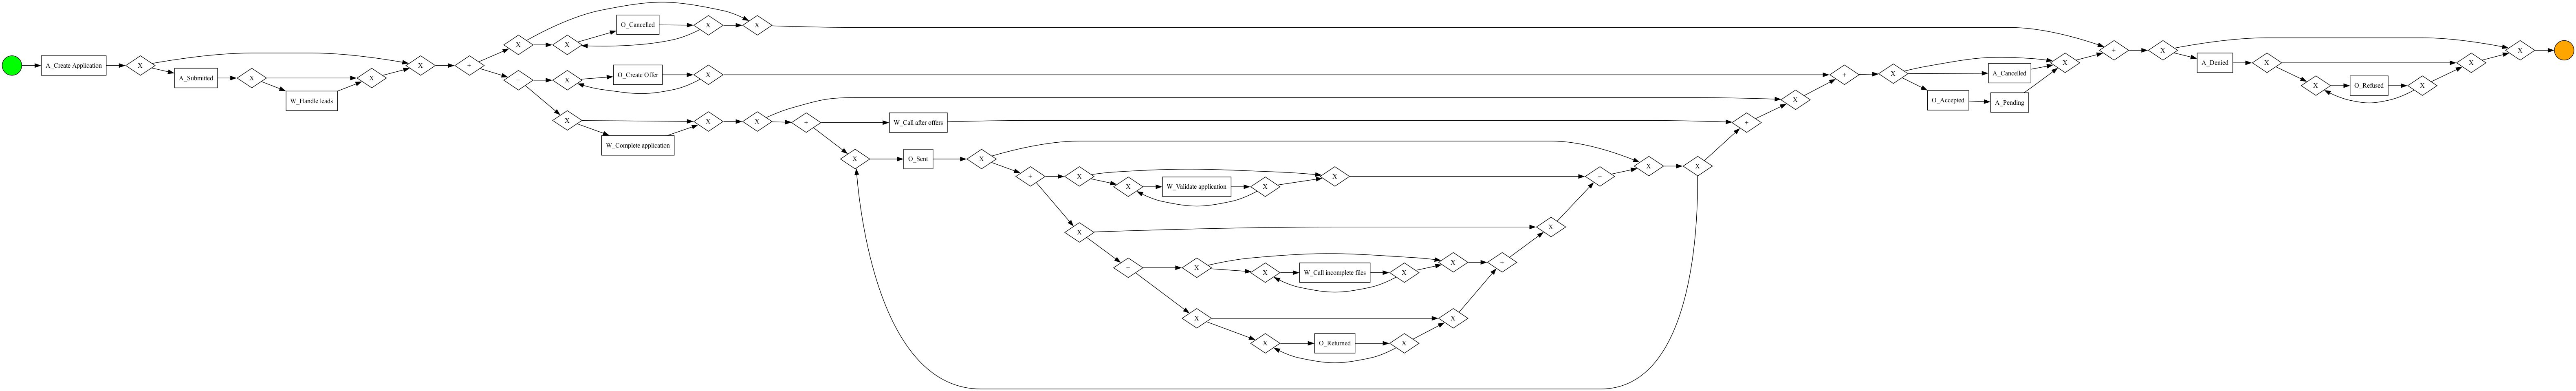

IM 0.2 (BPMN)


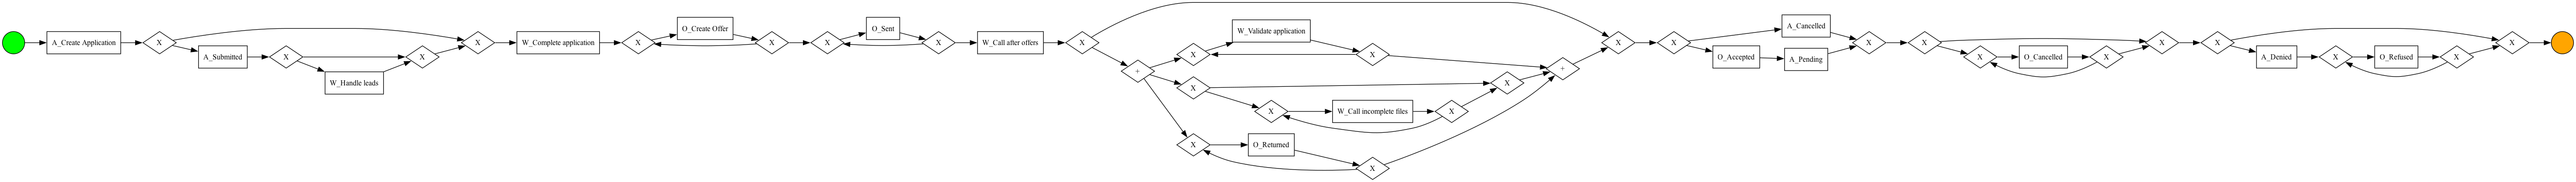

IM 0.4 (BPMN)


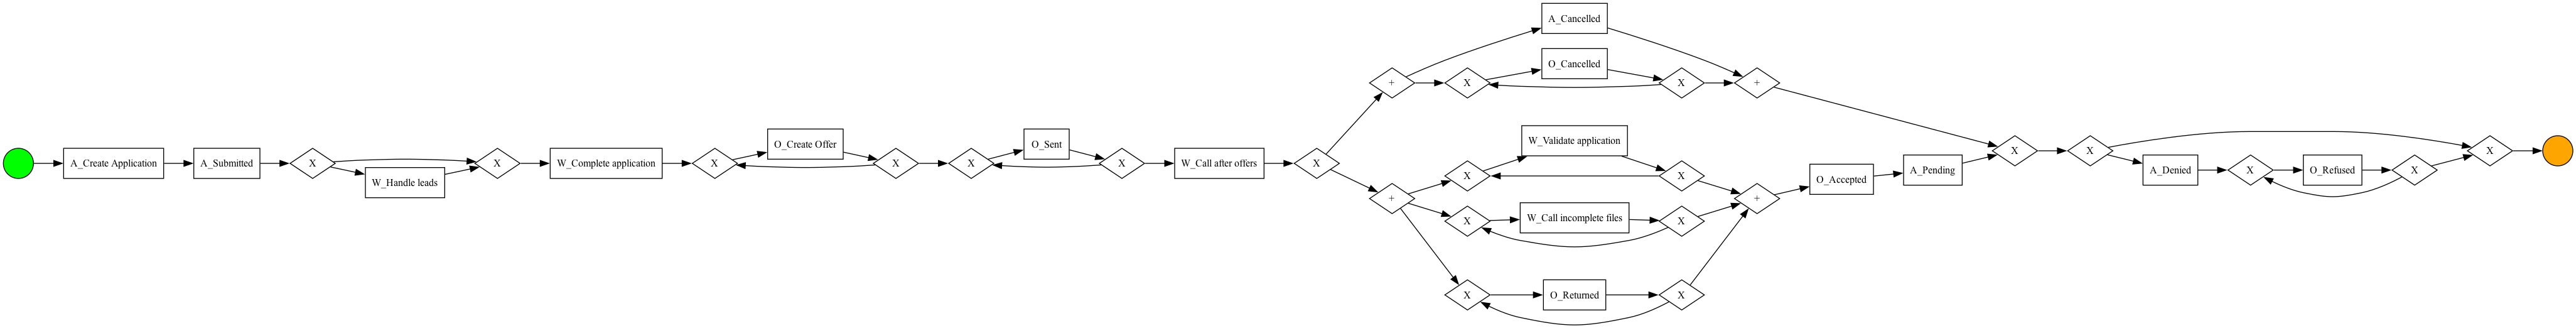

HM (Petri net)


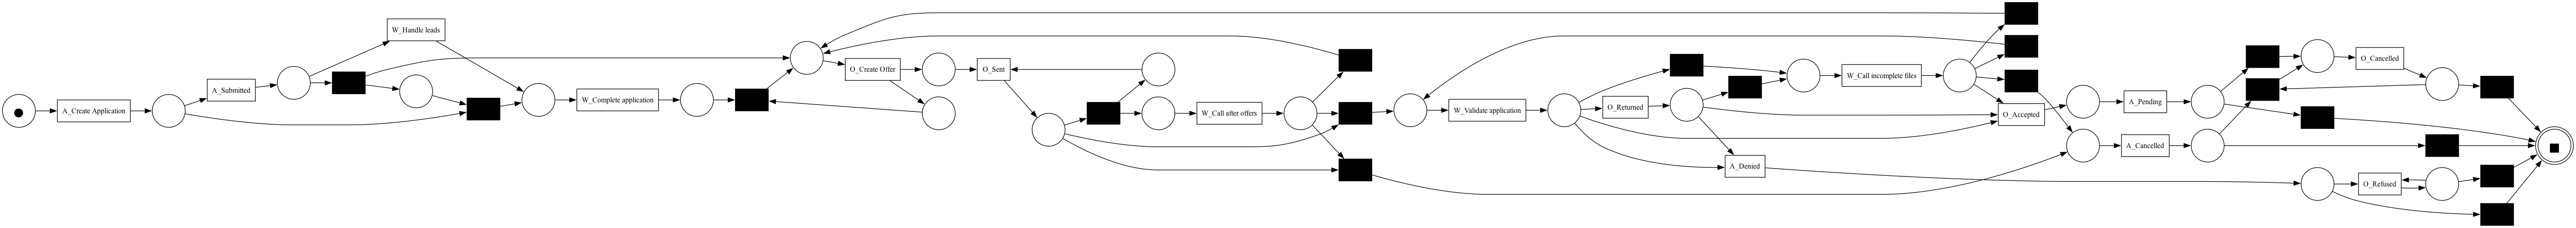

In [15]:
for name, (_, _, _, bpmn) in models.items():
    mid = f"{LEVEL}__{name.replace(' ', '_')}"
    net, im, fm, _ = models[name]
    print(name, "(Petri net)" if name == "HM" else "(BPMN)")
    if name == "HM":
        pm4py.view_petri_net(net, im, fm, rankdir="LR")
    else:
        pm4py.view_bpmn(bpmn, rankdir="LR")

## 6. Output

* `src/abstraction_w.py`: log abstraction, checks; `src/evaluation.py`: metrics
* `models/discovery/L3_WOA__*.pnml` / `.bpmn`; `figures/discovery/L3_WOA__*` (BPMN, Petri net, DFG)
* `tables/w_level_*.csv` (activities, Table 2a row, pair check, O_Cancelled, DFG);
  `tables/discovery_quality.csv`, `tables/discovery_top_unfit.csv`